# E206 · Adaptive replay allocation for SimSiam

Can different amounts of current and historical training improve learning at different points in a shifting stream?

Each policy uses the existing Late4 SimSiam learner on DINO ViT-B/16, with settled heads. It takes one optimizer update on 32 images per arriving minibatch. The 672-minibatch walk is A → B → A → C → B → D → A with 96 minibatches per regime. Each arrival enters the memory even if it was replaced in the training batch. Replay draws from earlier arrivals. The recent pool covers the last 256 observed images. Only the very first batch has no available replay.

## Progress

**Phase C complete · predictor gate not met**  
Updated 2026-11-21T04:17:31.749779+01:00.

Phase A/B trajectories **12/12**. Phase C branches **216/216**.

## Measurements

- **Current learning.** For each post-shift block, compare its own regime probe at entry and exit.
- **Retention.** For each historical regime, compare the score to its most recent exit. Average the available historical banks.
- **Overall quality.** Integrate the five linear-task accuracies over the trajectory. Scene kNN, backbone LiDAR and RankMe, and within-regime retrieval margins remain visible separately.
- **Evaluation sample size.** The fixed regime banks have 64 images each. Probe support is recorded by task and bank. Regime utility averages supported tasks, which can differ across regimes.

The frontier uses paired seed effects relative to no replay. Phase C starts only if the mean current learning or historical retention benefit is at least **0.5 pp**, with positive effects in at least two seeds. It uses 24 origins, three replay rates and three independent paired draws. No labeled scores enter the training policy. The branch oracle uses labels for diagnosis and is evaluated on a draw excluded from its action choice.

## Fixed-policy frontier

| Policy | Unique current images trained | Replay slots | Train + decode (min) | Time-avg. linear probes |
| --- | --- | --- | --- | --- |
| No replay | 21504 | 0 | 4.4 | 63.07% |
| Recent 25% | 16136 | 5368 | 4.4 | 62.93% |
| Broad 25% | 16136 | 5368 | 4.5 | 62.96% |
| Broad 50% | 10768 | 10736 | 4.4 | 62.88% |

Means across the three paired seeds. Each run observes 21,504 current images and trains for 672 updates.

### Paired effects versus no replay (pp)

| Policy | Current learning | Retention | Time-avg. linear | Endpoint linear | Time-avg. scene kNN |
| --- | --- | --- | --- | --- | --- |
| Recent 25% | +0.575 | +0.165 | -0.136 | +0.193 | -0.022 |
| Broad 25% | +0.131 | +0.489 | -0.107 | +0.015 | -0.970 |
| Broad 50% | +0.837 | -0.354 | -0.191 | +0.078 | -2.285 |

**Phase C gate passed.**

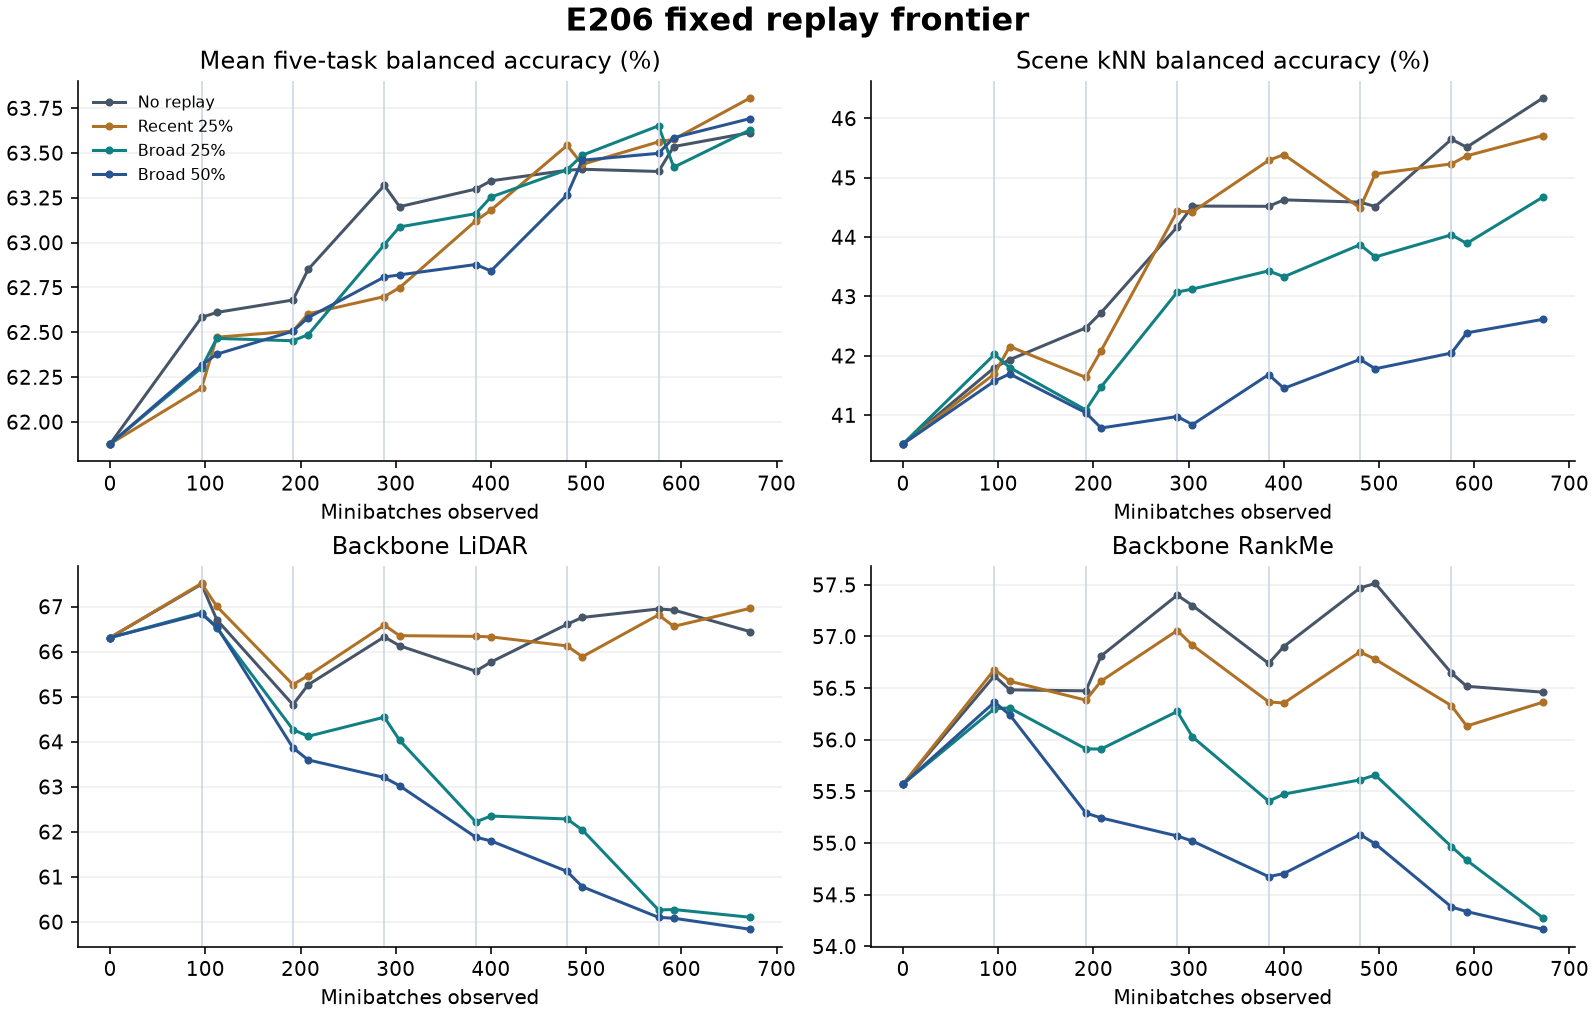

## Phase C · Independent-draw oracle

The oracle selected a replay rate on two draws and was scored on the third. Utility gives equal weight to the current bank and mean historical-bank score when history is available.

**Gain versus best fixed (No replay)** -0.072 pp [-0.127, -0.030]. The interval is a descriptive seed bootstrap.

| Seed | Gain (pp) |
| --- | --- |
| 1 | -0.127 |
| 2 | -0.060 |
| 3 | -0.030 |

**One-step predictor gate** did not pass. A predictor study needs first-action branches with a common continuation for a one-minibatch decision. These sustained-rate branches estimate the effect of a 32-minibatch intervention.